# DNAscape mapping atlas

This notebook introduces `rmap`, the DNAscape workflow for mapping between replication features through mathematical relationships derived under explicit mechanistic assumptions. Rather than simulating individual S phases, `rmap` uses deterministic transformations or fitted kinetic quantities to move between features such as replication timing, fork directionality, origin firing activity, among others. It is therefore designed for well-defined scenarios in which the supplied data and the target quantity are expected to be linked by a specific modelling assumption.

The notebook is organised by **target feature**: first decide what you want to infer, then provide the data or kinetic quantities needed to infer it. In `rmap`, `source` contains the supplied replication data or model-derived quantities, while `assumptions` contains the settings that define the mapping route, such as `resolution_x`, geometry, target form and fitting controls.

**Data types.** We use replication timing (RT) as the main entry point and consider four targets: origin firing, fork speed, joint kinetic fields and replication timing itself. The arrays used by the model should be interpreted as kinetic representations of the underlying biology, rather than raw assay values. They should therefore be preprocessed according to the biological question being asked. See `1_datamanagement.ipynb` for details on data preparation and formatting.

**Space-time dependence.** When `rmap` is used to infer either `firing_rate` or `fork_speed`, `target_form` specifies the dependency structure of the inferred quantity: `constant` for a single fitted value, `space` for an $x$-dependent profile, `time` for a time-dependent profile and `spacetime` for a full $(x,t)$ field. If `target_form` is omitted, `rmap` defaults to `space` for both targets. 

**Fitting errors.** As the expected RT is uniquely determined from initiation rate and fork speed, the goodness of each fit and mapping is evaluated with the mean square error (MSE) between a reference timing profile and the predicted one.

## Setup

Autoreload keeps notebook runs aligned with source-code edits.

In [1]:
%reload_ext autoreload
%autoreload 2

from dnascape import *

### Inspecting available mappings

Use `rmap.available()` for a simple overview of what can be inferred, which source data are needed and which assumptions can be adjusted. The public table is grouped by target and source data, so each input combination appears only once; data supplied through default assumptions are still shown as required data. For a narrower view, use `rmap.requirements(target="firing_rate")`. For internal development, `rmap.development()` keeps the full per-method registry with method names and implementation status.

In [2]:
rmap.available()

,target,source (required data),assumptions,target description
0,firing_rate,"replication_timing, fork_speed","target_form, resolution_x, neighbourhood_range...",Origin firing activity to be inferred or suppl...
1,fork_directionality,"firing_rate, fork_speed","sim_number, resolution_x, resolution_t, perQ, ...",Net fork movement directionality along genomic...
2,fork_directionality,"replication_timing, fork_speed","resolution_x, T0, smoothw, perQ",Net fork movement directionality along genomic...
3,fork_speed,"replication_timing, firing_rate","resolution_x, neighbourhood_range, fit_step, m...",Fork progression speed to be inferred or suppl...
4,replication_timing,"firing_rate, fork_speed","resolution_x, neighbourhood_range, perQ, genom...",Replication timing profile along genomic posit...
5,replication_timing,"fork_directionality, fork_speed","resolution_x, T0, smoothw, perQ",Replication timing profile along genomic posit...


In [3]:

rmap.requirements(target="firing_rate")

,target,source (required data),assumptions,target description
0,firing_rate,"replication_timing, fork_speed","target_form, resolution_x, neighbourhood_range...",Origin firing activity to be inferred or suppl...


## Example data

We use the bundled hESC chromosome 1 replication-timing profile. The selected profile is a one-dimensional `T(x)` array, and `positions_kb` gives the matching genomic coordinates.

In [4]:
chr_number = 1
interval_kb = (0, 60_000)

replication_timing_full = loadcsv(
    "example",
    example="replication_timing_hESC",
    chr_number=chr_number,
)

replication_timing, positions_kb = select_profile_region(
    replication_timing_full,
    interval_kb=interval_kb,
)

n_positions = replication_timing.size

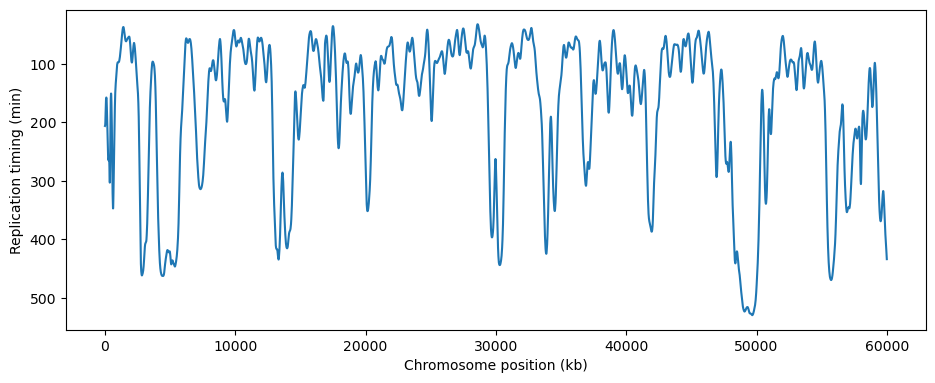

In [5]:
plotf(
    replication_timing,
    x_array=positions_kb,
    invyQ=True,
    xtitle="Chromosome position (kb)",
    ytitle="Replication timing (min)",
)

## Core mapping routes

The table summarises the central kinetic triangle: timing `T(x)`, firing `I`, and fork speed `v`. Constant, spatial, time-only, and space-time forms are labelled as `I0`, `I(x)`, `I(t)`, `I(x,t)` and `v0`, `v(x)`, `v(t)`, `v(x,t)`.

Rows marked **implemented** are available now. The current deterministic methods cover the constant-speed cases involving `I0` or `I(x)`. In the examples below, every route is plotted with the same row order: origin firing, fork speed, and replication timing. Labels mark the target, and the timing row includes an `rsim` timing trace generated from the same firing-rate and fork-speed inputs.

In [6]:
rmap.development()

,target,required data,data forms,required assumptions,optional assumptions,assumption forms,assumption values,method,status,description
0,replication_timing,"firing_rate, fork_speed",firing_rate: scalar/x; fork_speed: scalar/x,-,"resolution_x, neighbourhood_range, perQ, n_bin...",-,-,firing_and_speed_to_timing_deterministic,implemented,Deterministic mapping for I0 or I(x) with v0 o...
1,replication_timing,"firing_rate, fork_speed",firing_rate: scalar/x/t/xt; fork_speed: t/xt,-,"resolution_x, neighbourhood_range, perQ, n_bin...",-,-,firing_and_variable_speed_to_timing,needs method,Forward timing maps with time-only or space-ti...
2,firing_rate,"replication_timing, fork_speed",replication_timing: x; fork_speed: scalar,target_form,"resolution_x, neighbourhood_range, fit_step, m...",-,target_form: constant,timing_and_speed_to_constant_firing_rate,implemented,Scalar fit of I0 from timing and constant fork...
3,firing_rate,"replication_timing, fork_speed",replication_timing: x; fork_speed: scalar,-,"resolution_x, neighbourhood_range, fit_step, m...",-,target_form: space,timing_and_speed_to_firing_rate,implemented,Iterative fit of I(x) from timing and constant...
4,firing_rate,"replication_timing, fork_speed",replication_timing: x; fork_speed: x/t/xt,-,"resolution_x, neighbourhood_range, fit_step, m...",-,target_form: constant/space,timing_and_variable_speed_to_firing_rate,needs method,Fitting scalar or space-dependent firing rate ...
5,fork_speed,"replication_timing, firing_rate",replication_timing: x; firing_rate: scalar/x,-,"resolution_x, neighbourhood_range, fit_step, m...",-,target_form: constant,timing_and_firing_to_constant_fork_speed,implemented,Scalar fit of v0 from timing and firing rate.
6,fork_speed,"replication_timing, firing_rate",replication_timing: x; firing_rate: scalar/x,-,"resolution_x, neighbourhood_range, fit_step, m...",-,target_form: space,timing_and_firing_to_spatial_fork_speed,implemented,Spatial effective fit of v(x) from timing and ...
7,fork_speed,"replication_timing, firing_rate",replication_timing: x; firing_rate: x,-,"resolution_x, resolution_t, neighbourhood_rang...",-,target_form: time,timing_and_firing_to_time_fork_speed,implemented,Time-only effective fit of v(t) from timing an...
8,fork_speed,"replication_timing, firing_rate",replication_timing: x; firing_rate: xt,-,"resolution_x, resolution_t, neighbourhood_rang...",-,target_form: spacetime,timing_and_firing_to_spacetime_fork_speed,implemented,"Space-time effective fit of v(x,t) from timing..."
9,fork_directionality,"replication_timing, fork_speed",replication_timing: x; fork_speed: scalar,-,"resolution_x, T0, smoothw, perQ",-,-,timing_and_speed_to_directionality,implemented,Gradient-based fork-directionality mapping.


## 1. Target: Initiation rate $I(x,t)$

Origin firing rate can be mapped from replication timing and fork speed, under various space-time assumptions on these features. We assume replication timing is given as a position-specific array. Depending on the shape of the fork speed source data (see `1_datamanagement.ipynb`), `rmap` automatically detects whether it is constant or if it varies in both space and/or time. To define the space-time dependency assumtpions on the firing rate, simply set `target_form` to either `constant`, `space`, `time`, or `spacetime`. The same logic applies when fitting fork speed, in Section 2.

### 1.1 Uniform initiation $I=I_0$

For instance, if we assume constant fork speed (a scalar input $v=v_0$) and want to infer a constant initiation rate (a scalar output $I=I_0$), we may set

In [7]:
fork_speed = 1.4

firing_rate_constant = rmap(
    source={
        "replication_timing": replication_timing,
        "fork_speed": fork_speed,
    },
    target="firing_rate",
    assumptions={
        "target_form": "constant"
    }
)

print(f"Optimal uniform firing rate: {firing_rate_constant}")

Optimal uniform firing rate: 3.974186867638273e-058300e+04


Because we selected `target_form='constant'`, `rmap` returns the optimal uniform initiation rate (a scalar $I_0$), that best matches the RT curve. We may then use this scalar and the constant fork speed to simulate the replication timing profile and have a way to compare with the timing data source. See `3_simulation.ipynb` for the full `rsim` usage details.

In [8]:
replication_timing_sim = rsim(
    source={
        "firing_rate": firing_rate_constant,
        "fork_speed": fork_speed,
    },
    assumptions={
        "sim_number": 100,
        "interval_kb": interval_kb,
    },
)["replication_timing"]

Which can be compared with the RT data

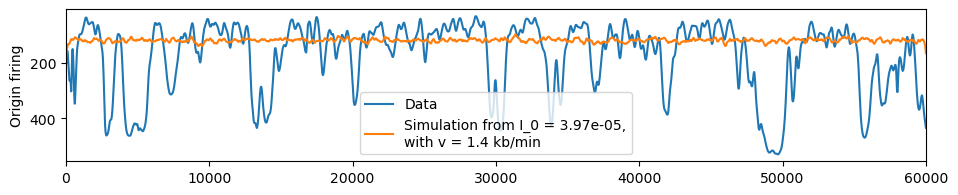

In [9]:
mplotf(
    [
        [replication_timing, replication_timing_sim],
    ],
    mlabels=[
        ["Data", f"Simulation from I_0 = {firing_rate_constant:.2e},\nwith v = {fork_speed} kb/min"],
    ],
    mx_array=positions_kb,
    minvyQ=[True],
    mxtitle=["", "", "Chromosome position (kb)"],
    mytitle=["Origin firing", "RT (min)"],
    figsize=(10, 1.9),
)

Although DNAscape tries to find the optimal $I_0$, the uniform assumption is not strong enough to to infer timing.

### 1.2 Space-dependent initiation $I(x)$

If consider a space-dependent initiation rate, $I(x)$, we may set

In [10]:
fork_speed = 1.4

firing_rate_space = rmap(
    source={
        "replication_timing": replication_timing,
        "fork_speed": fork_speed,
    },
    target="firing_rate",
    assumptions={
        "target_form": "space",
    }
)

Now, since `target_form='space'`, `rmap` returns an array where each entry corresponds to a firing rate at each kilobase. Again, we may use this array and the constant fork speed to simulate the replication timing profile.

In [11]:
replication_timing_sim = rsim(
    source={
        "firing_rate": firing_rate_space,
        "fork_speed": fork_speed,
    },
    assumptions={
        "sim_number": 100,
    },
)["replication_timing"]

We may then plot the fitted firing rate profile, with its corresponding timing profile and data reference.

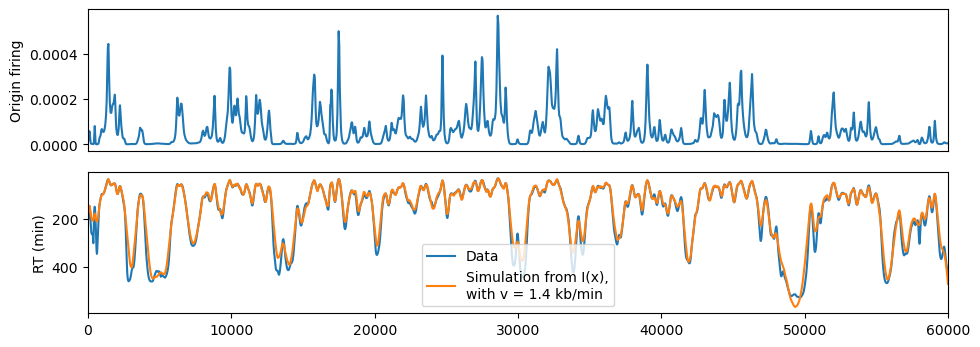

In [12]:
mplotf(
    [
        firing_rate_space,
        [replication_timing, replication_timing_sim],
    ],
    mlabels=[
        None,
        ["Data", f"Simulation from I(x),\nwith v = {fork_speed} kb/min"],
    ],
    mx_array=positions_kb,
    minvyQ=[False, True],
    mxtitle=["", "", "Chromosome position (kb)"],
    mytitle=["Origin firing", "RT (min)"],
    figsize=(10, 1.9),
)

### 1.3 Time-dependent initiation $I(t)$

A time-only initiation profile is useful when the biological hypothesis is that origin firing changes during S phase but is shared across the selected genomic interval. Here `rmap` first fits the spatial profile implied by the timing data and then projects it onto the timing coordinate, returning a row vector interpreted as `I(t)`.

In [13]:
firing_rate_time = rmap(
    source={
        "replication_timing": replication_timing,
        "fork_speed": fork_speed,
    },
    target="firing_rate",
    assumptions={
        "target_form": "time",
        "resolution_t": 5,
        "space_fit_step": 0.6,
        "space_maxiter": 10,
        "temporal_fit_step": 0.35,
        "temporal_maxiter": 2,
        "temporal_sim_number": 20,
        "refine_ratio_bounds": (0.25, 4.0),
        "refine_seed": 1,
    }
)

In [14]:
replication_timing_sim_time = rsim(
    source={
        "firing_rate": firing_rate_time,
        "fork_speed": fork_speed,
    },
    assumptions={
        "sim_number": 100,
        "interval_kb": interval_kb,
        "resolution_t": 5,
    },
)["replication_timing"]

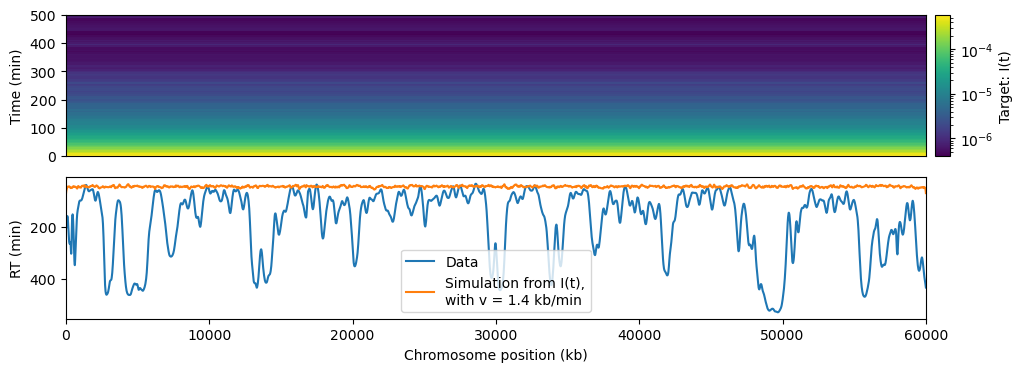

In [15]:
mplotf(
    [
        firing_rate_time,
        [replication_timing, replication_timing_sim_time],
    ],
    mlabels=[
        ["Target: I(t)"],
        ["Data", f"Simulation from I(t),\nwith v = {fork_speed} kb/min"],
    ],
    mx_array=positions_kb,
    mresolution_t=[5, 1],
    minvyQ=[False, True],
    mlogzQ=[True, False],
    mxtitle=["", "Chromosome position (kb)"],
    mytitle=["Time (min)", "RT (min)"],
    figsize=(10, 1.9),
)

### 1.4 Spacetime-dependent initiation $I(x,t)$

A full space-time initiation field keeps both genomic position and S-phase time explicit. In this first implemented route, `rmap` combines the fitted spatial profile with its timing-coordinate projection, returning a matrix interpreted as `I(x,t)`.

In [16]:
firing_rate_spacetime = rmap(
    source={
        "replication_timing": replication_timing,
        "fork_speed": fork_speed,
    },
    target="firing_rate",
    assumptions={
        "target_form": "spacetime",
        "resolution_t": 5,
        "space_fit_step": 0.6,
        "space_maxiter": 10,
        "spacetime_space_fit_step": 0.25,
        "spacetime_time_fit_step": 0.25,
        "spacetime_maxiter": 2,
        "spacetime_sim_number": 20,
        "refine_ratio_bounds": (0.25, 4.0),
        "refine_seed": 2,
    }
)

In [17]:
replication_timing_sim_spacetime = rsim(
    source={
        "firing_rate": firing_rate_spacetime,
        "fork_speed": fork_speed,
    },
    assumptions={
        "sim_number": 100,
        "resolution_t": 5,
    },
)["replication_timing"]

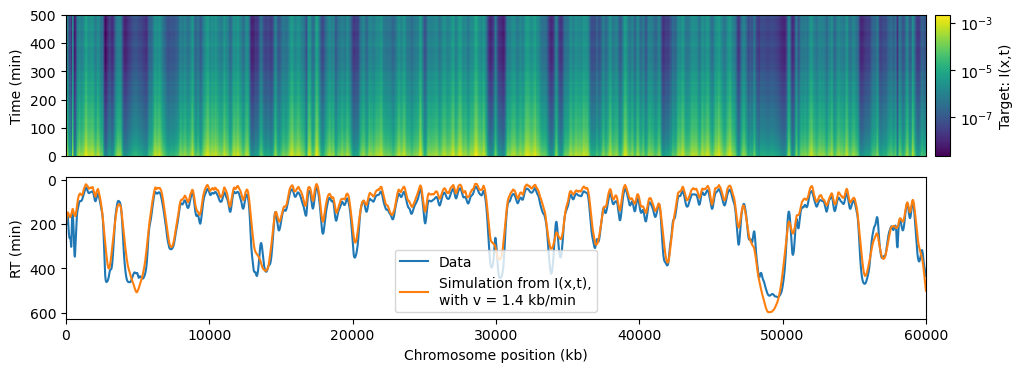

In [18]:
mplotf(
    [
        firing_rate_spacetime,
        [replication_timing, replication_timing_sim_spacetime],
    ],
    mlabels=[
        ["Target: I(x,t)"],
        ["Data", f"Simulation from I(x,t),\nwith v = {fork_speed} kb/min"],
    ],
    mx_array=positions_kb,
    mresolution_t=[5, 1],
    minvyQ=[False, True],
    mlogzQ=[True, False],
    mxtitle=["", "Chromosome position (kb)"],
    mytitle=["Time (min)", "RT (min)"],
    figsize=(10, 1.9),
)

## 2. Target: Fork speed $v(x,t)$

Fork speed can be mapped from replication timing when origin firing is supplied as the second kinetic input. Here we keep timing fixed as the data source and vary the firing-rate form: a uniform rate $I_0$, a spatial profile $I(x)$, or the space-time field $I(x,t)$ estimated above. As in Section 1, `target_form` defines whether the inferred fork speed is spatial, temporal, or space-time dependent.

### 2.1 Uniform initiation $I_0$ to spatial fork speed $v(x)$

With a uniform initiation baseline, `rmap` asks how much regional fork-speed variation is needed to explain the timing profile.

In [19]:
fork_speed_space_from_I0 = rmap(
    source={
        "replication_timing": replication_timing,
        "firing_rate": firing_rate_constant,
    },
    target="fork_speed",
    assumptions={
        "target_form": "space",
        "initial_fork_speed": fork_speed,
        "space_fit_step": 0.4,
        "space_maxiter": 40,
        "smoothw": 100,
    }
)

In [20]:
replication_timing_sim_speed_I0_space = rsim(
    source={
        "firing_rate": firing_rate_constant,
        "fork_speed": fork_speed_space_from_I0,
    },
    assumptions={
        "sim_number": 100,
    },
)["replication_timing"]

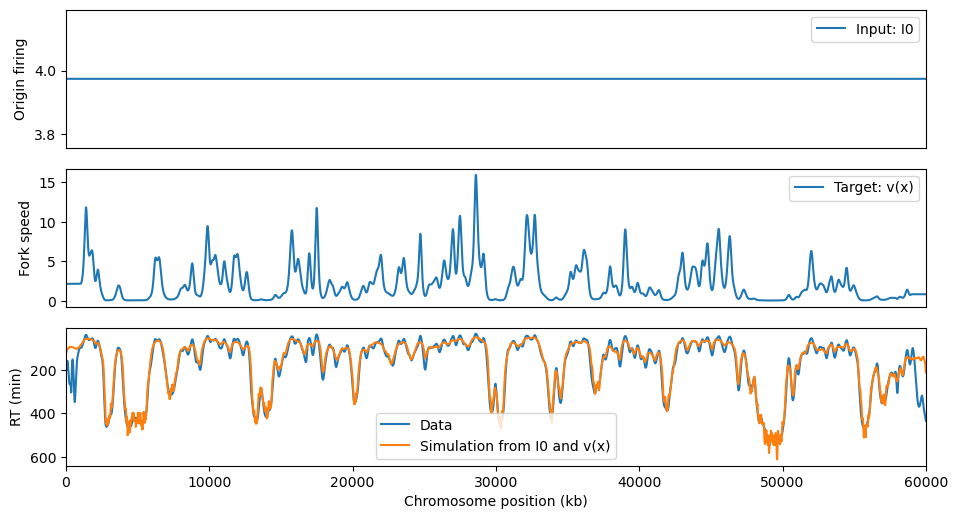

In [21]:
mplotf(
    [
        np.full(n_positions, firing_rate_constant),
        fork_speed_space_from_I0,
        [replication_timing, replication_timing_sim_speed_I0_space],
    ],
    mlabels=[
        ["Input: I0"],
        ["Target: v(x)"],
        ["Data", "Simulation from I0 and v(x)"],
    ],
    mx_array=positions_kb,
    minvyQ=[False, False, True],
    mxtitle=["", "", "Chromosome position (kb)"],
    mytitle=["Origin firing", "Fork speed", "RT (min)"],
    figsize=(10, 1.9),
)

### 2.2 Spatial initiation $I(x)$ to spatial fork speed $v(x)$

When initiation is already spatially resolved, the fitted speed profile captures the remaining positional structure needed to match timing.

In [22]:
fork_speed_space_from_Ix = rmap(
    source={
        "replication_timing": replication_timing,
        "firing_rate": firing_rate_space,
    },
    target="fork_speed",
    assumptions={
        "target_form": "space",
        "initial_fork_speed": fork_speed,
        "space_fit_step": 0.4,
        "space_maxiter": 40,
        "smoothw": 100,
    }
)

In [23]:
replication_timing_sim_speed_Ix_space = rsim(
    source={
        "firing_rate": firing_rate_space,
        "fork_speed": fork_speed_space_from_Ix,
    },
    assumptions={
        "sim_number": 100,
    },
)["replication_timing"]

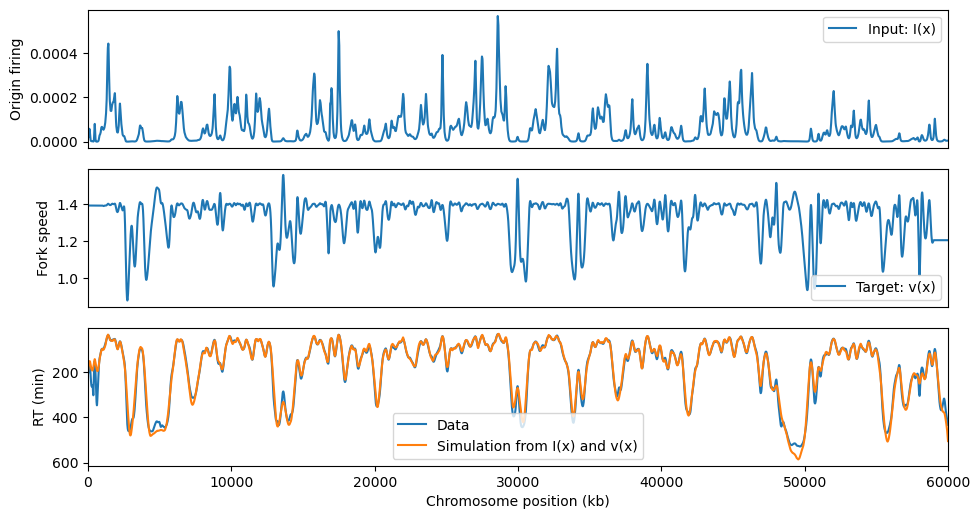

In [24]:
mplotf(
    [
        firing_rate_space,
        fork_speed_space_from_Ix,
        [replication_timing, replication_timing_sim_speed_Ix_space],
    ],
    mlabels=[
        ["Input: I(x)"],
        ["Target: v(x)"],
        ["Data", "Simulation from I(x) and v(x)"],
    ],
    mx_array=positions_kb,
    minvyQ=[False, False, True],
    mxtitle=["", "", "Chromosome position (kb)"],
    mytitle=["Origin firing", "Fork speed", "RT (min)"],
    figsize=(10, 1.9),
)

### 2.3 Spatial initiation $I(x)$ to time-dependent fork speed $v(t)$

This route compresses the spatial speed fit onto the S-phase time coordinate, then optionally refines the temporal profile using simulation-backed timing residuals.

In [25]:
fork_speed_time_from_Ix = rmap(
    source={
        "replication_timing": replication_timing,
        "firing_rate": firing_rate_space,
    },
    target="fork_speed",
    assumptions={
        "target_form": "time",
        "resolution_t": 5,
        "initial_fork_speed": fork_speed,
        "space_fit_step": 0.4,
        "space_maxiter": 40,
        "temporal_fit_step": 0.35,
        "temporal_maxiter": 2,
        "temporal_sim_number": 20,
        "refine_ratio_bounds": (0.25, 4.0),
        "refine_seed": 3,
        "smoothw": 100,
    }
)

In [26]:
replication_timing_sim_speed_Ix_time = rsim(
    source={
        "firing_rate": firing_rate_space,
        "fork_speed": fork_speed_time_from_Ix,
    },
    assumptions={
        "sim_number": 100,
        "resolution_t": 5,
    },
)["replication_timing"]

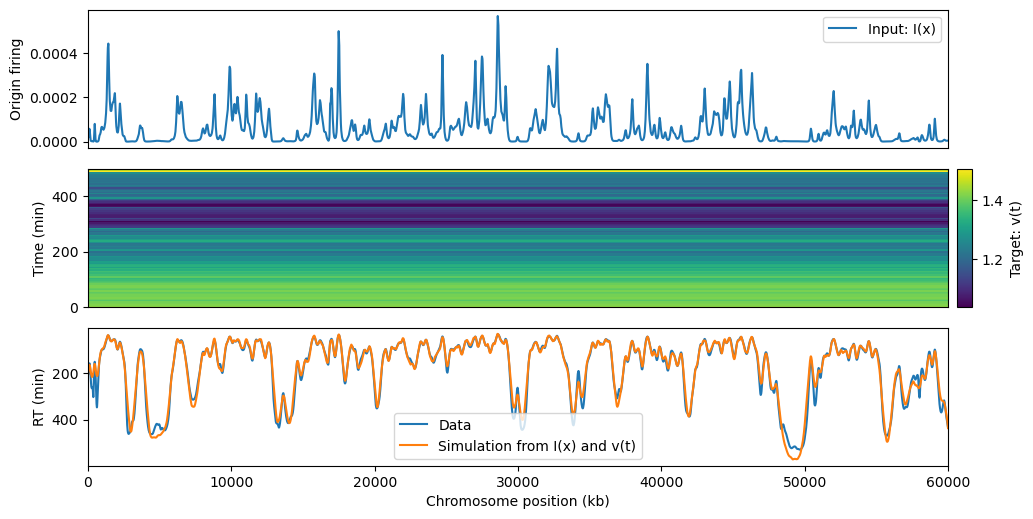

In [27]:
mplotf(
    [
        firing_rate_space,
        fork_speed_time_from_Ix,
        [replication_timing, replication_timing_sim_speed_Ix_time],
    ],
    mlabels=[
        ["Input: I(x)"],
        ["Target: v(t)"],
        ["Data", "Simulation from I(x) and v(t)"],
    ],
    mx_array=positions_kb,
    mresolution_t=[1, 5, 1],
    minvyQ=[False, False, True],
    mxtitle=["", "", "Chromosome position (kb)"],
    mytitle=["Origin firing", "Time (min)", "RT (min)"],
    figsize=(10, 1.9),
)

### 2.4 Space-time initiation $I(x,t)$ to space-time fork speed $v(x,t)$

The most general case keeps both axes explicit. The first implemented route builds a separable space-time speed field from the spatial speed fit and its timing-coordinate projection, with optional lightweight refinement.

In [28]:
fork_speed_spacetime_from_Ixt = rmap(
    source={
        "replication_timing": replication_timing,
        "firing_rate": firing_rate_spacetime,
    },
    target="fork_speed",
    assumptions={
        "target_form": "spacetime",
        "resolution_t": 5,
        "initial_fork_speed": fork_speed,
        "space_fit_step": 0.4,
        "space_maxiter": 40,
        "spacetime_space_fit_step": 0.25,
        "spacetime_time_fit_step": 0.25,
        "spacetime_maxiter": 2,
        "spacetime_sim_number": 20,
        "refine_ratio_bounds": (0.25, 4.0),
        "refine_seed": 4,
        "smoothw": 100,
    }
)

In [29]:
replication_timing_sim_speed_Ixt_spacetime = rsim(
    source={
        "firing_rate": firing_rate_spacetime,
        "fork_speed": fork_speed_spacetime_from_Ixt,
    },
    assumptions={
        "sim_number": 100,
        "resolution_t": 5,
    },
)["replication_timing"]

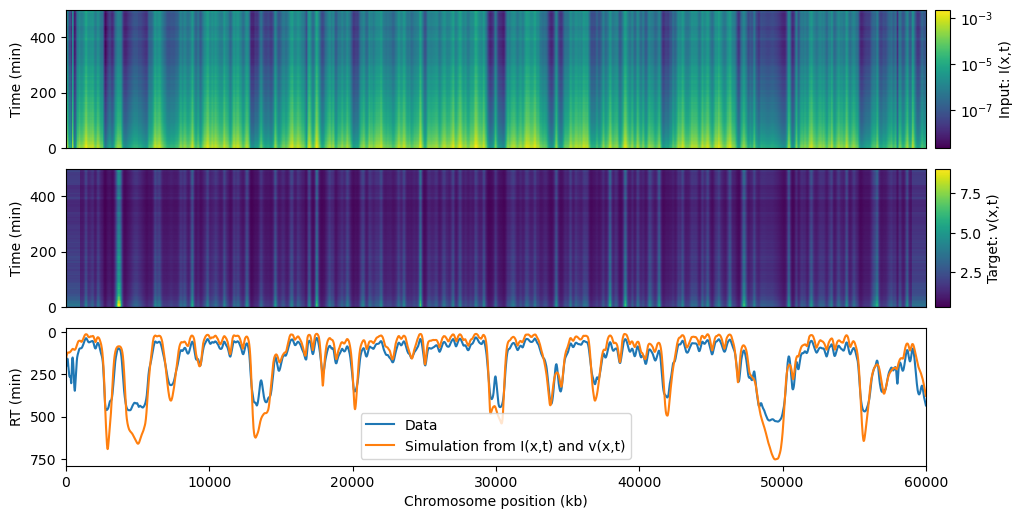

In [30]:
mplotf(
    [
        firing_rate_spacetime,
        fork_speed_spacetime_from_Ixt,
        [replication_timing, replication_timing_sim_speed_Ixt_spacetime],
    ],
    mlabels=[
        ["Input: I(x,t)"],
        ["Target: v(x,t)"],
        ["Data", "Simulation from I(x,t) and v(x,t)"],
    ],
    mx_array=positions_kb,
    mresolution_t=[5, 5, 1],
    minvyQ=[False, False, True],
    mlogzQ=[True, False, False],
    mxtitle=["", "", "Chromosome position (kb)"],
    mytitle=["Time (min)", "Time (min)", "RT (min)"],
    figsize=(10, 1.9),
)

## 3. Target: joint kinetic fields $I(x,t)$ and $v(x,t)$

This route uses replication timing alone to fit initiation and fork-speed fields simultaneously. It is different from first estimating $I(x,t)$ and then fitting $v(x,t)$: both fields are updated together from the same timing residual, giving one compatible kinetic decomposition of the data. The solution is not unique, and the flexibility of two full space-time fields can naturally overfit timing; the point here is to showcase the most expressive mapping option when that flexibility is useful.

In [ ]:
joint_kinetics = rmap(
    source="replication_timing",
    data=replication_timing,
    target="kinetic_fields",
    assumptions={
        "target_form": "spacetime",
        "resolution_t": 5,
        "initial_fork_speed": fork_speed,
        "joint_maxiter": 3,
        "joint_sim_number": 20,
        "firing_space_fit_step": 0.12,
        "firing_time_fit_step": 0.08,
        "speed_space_fit_step": 0.12,
        "speed_time_fit_step": 0.08,
        "refine_ratio_bounds": (0.25, 4.0),
        "refine_seed": 5,
    },
)

firing_rate_joint = joint_kinetics["firing_rate"]
fork_speed_joint = joint_kinetics["fork_speed"]
joint_kinetics["fit_history"]

The fitted fields can be sent directly to `rsim`. The timing row below compares the original RT data with a stochastic simulation driven by the jointly fitted kinetics.

In [ ]:
replication_timing_sim_joint = rsim(
    source={
        "firing_rate": firing_rate_joint,
        "fork_speed": fork_speed_joint,
    },
    assumptions={
        "sim_number": 100,
        "resolution_t": 5,
        "seed": 41,
    },
)["replication_timing"]

In [ ]:
mplotf(
    [
        firing_rate_joint,
        fork_speed_joint,
        [replication_timing, replication_timing_sim_joint],
    ],
    mlabels=[
        ["Target: jointly fitted I(x,t)"],
        ["Target: jointly fitted v(x,t)"],
        ["Data", "Simulation from jointly fitted kinetics"],
    ],
    mx_array=positions_kb,
    mresolution_t=[5, 5, 1],
    minvyQ=[False, False, True],
    mlogzQ=[True, False, False],
    mxtitle=["", "", "Chromosome position (kb)"],
    mytitle=["Time (min)", "Time (min)", "RT (min)"],
    figsize=(10, 1.9),
)

## 4. Target: replication timing

Use this target when firing and fork speed are supplied and the goal is a predicted timing profile.

### 4.1 I0 and v0 to timing

A scalar firing rate needs `interval_kb` so DNAscape knows the length of the returned profile.

In [ ]:
constant_timing_fit = rmap(
    source={
        "firing_rate": fitted_I0,
        "fork_speed": fitted_v0_from_I0,
    },
    target="replication_timing",
    assumptions={
        "resolution_x": output_resolution_kb,
        "interval_kb": interval_kb,
    },
    return_info=True,
)

timing_from_I0 = constant_timing_fit["values"]
sim_timing_from_I0 = rsim(
    source={
        "firing_rate": fitted_I0,
        "fork_speed": fitted_v0_from_I0,
    },
    assumptions={
        "sim_number": simulation_replicates,
        "resolution_x": output_resolution_kb,
        "interval_kb": interval_kb,
        "seed": 31,
        "verbose": False,
    },
)["replication_timing"]

print(constant_timing_fit["method"], timing_from_I0.shape)

In [ ]:
mplotf(
    [
        np.full(n_positions, fitted_I0),
        np.full(n_positions, fitted_v0_from_I0),
        [replication_timing, timing_from_I0, sim_timing_from_I0],
    ],
    mlabels=[
        ["Input: fitted I0"],
        ["Input: fitted v0"],
        ["Reference: timing data", "Target: timing from I0", "rsim: I0 + v0"],
    ],
    mx_array=[positions_kb, positions_kb, positions_kb],
    minvyQ=[False, False, True],
    mxtitle=["", "", "Chromosome position (kb)"],
    mytitle=["Origin firing", "Fork speed", "Replication timing (min)"],
    figsize=(10, 1.9),
    hspace=0.16,
)

### 4.2 I(x) and v0 to timing

The spatial firing profile maps forward to a timing profile over the same genomic bins.

In [ ]:
spatial_timing_fit = rmap(
    source={
        "firing_rate": firing_rate,
        "fork_speed": fitted_v0_from_Ix,
    },
    target="replication_timing",
    assumptions={
        "resolution_x": output_resolution_kb,
    },
    return_info=True,
)

timing_from_Ix = spatial_timing_fit["values"]
sim_timing_from_Ix = rsim(
    source={
        "firing_rate": firing_rate,
        "fork_speed": fitted_v0_from_Ix,
    },
    assumptions={
        "sim_number": simulation_replicates,
        "resolution_x": output_resolution_kb,
        "interval_kb": interval_kb,
        "seed": 32,
        "verbose": False,
    },
)["replication_timing"]

print(spatial_timing_fit["method"], timing_from_Ix.shape)

In [ ]:
mplotf(
    [
        firing_rate,
        np.full(n_positions, fitted_v0_from_Ix),
        [replication_timing, timing_from_Ix, sim_timing_from_Ix],
    ],
    mlabels=[
        ["Input: fitted I(x)"],
        ["Input: fitted v0"],
        ["Reference: timing data", "Target: timing from I(x)", "rsim: I(x) + v0"],
    ],
    mx_array=[positions_kb, positions_kb, positions_kb],
    minvyQ=[False, False, True],
    mxtitle=["", "", "Chromosome position (kb)"],
    mytitle=["Origin firing", "Fork speed", "Replication timing (min)"],
    figsize=(10, 1.9),
    hspace=0.16,
)

## 5. Combined view

This final panel compares the constant and spatial routes on the same interval.

In [ ]:
mplotf(
    [
        [np.full(n_positions, fitted_I0), firing_rate],
        [np.full(n_positions, fitted_v0_from_I0), np.full(n_positions, fitted_v0_from_Ix)],
        [replication_timing, timing_from_I0, timing_from_Ix, sim_timing_from_I0, sim_timing_from_Ix],
    ],
    mlabels=[
        ["Fitted I0", "Fitted I(x)"],
        ["v0 from I0", "v0 from I(x)"],
        ["Timing data", "Timing from I0", "Timing from I(x)", "rsim: I0 + v0", "rsim: I(x) + v0"],
    ],
    mx_array=[positions_kb, positions_kb, positions_kb],
    minvyQ=[False, False, True],
    mxtitle=["", "", "Chromosome position (kb)"],
    mytitle=[
        "Firing rate",
        "Fork speed",
        "Replication timing (min)",
    ],
    figsize=(10, 2.3),
    hspace=0.18,
)